## 0. Load

In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
 
import cartopy.crs as ccrs # Cartography library
from matplotlib import pyplot as plt # Standard Plotting library
import numpy as np # Standard array library
import pandas as pd # Libary to work with labeled data frames and time series
import seaborn as sns # Makes plots more beautiful
import xarray as xr # Libary to work with labeled n-dimensional data and dask

cdo gendis,grid_1x1.txt -setgrid,icon_grid_0010_R02B04_G.nc /wolke_scratch/rvella/shared/dragomir/test01/test01_atm_2d_ml_20080830T000000Z.nc weights.nc

In [2]:
atm_data_3d = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/atm_3d_remap_test.nc")

In [3]:
atm_data_3d["cli"].encoding

{'zlib': False,
 'szip': False,
 'zstd': False,
 'bzip2': False,
 'blosc': False,
 'shuffle': False,
 'complevel': 0,
 'fletcher32': False,
 'contiguous': False,
 'chunksizes': (1, 1, 120, 240),
 'source': '/wolke_scratch/dnikolo/ICON_Data/atm_3d_remap_test.nc',
 'original_shape': (96, 47, 120, 240),
 'dtype': dtype('float64')}

## 2 Generate filtered output

In [28]:
#Libraries
import os
import sys
import dask
import warnings
import netCDF4 as nc
import numpy as np
import xarray as xr
import datetime
import cftime
from dask.diagnostics import ProgressBar


In [29]:

#--------------------------------------------------------------
#Helper functions 
#--------------------------------------------------------------

def time_filter(data):
    winter_month = list([1,2,11,12])
    time_months = data['time'].dt.month
    time_mask = time_months.isin(winter_month)
    data = data.where(time_mask, drop=True)
    return data

def lat_lon_filter(data):
    lat_mask = ((data['lat'] >= 30) & (data['lat'] <= 80)) | ((data['lat'] >= -80) & (data['lat'] <= -30))
    lon_mask = (data['lon'] >= -80) | (data['lon'] <= 80)
    data = data.where(lat_mask & lon_mask, drop=True)
    return data

In [30]:
#--------------------------------------------------------------
#Input data 
#--------------------------------------------------------------
#Folder path
folder_path = "/wolke_scratch/dnikolo/ICON_Data/"
array_path = "/wolke_scratch/dnikolo/ICON_Data/Cloud_top_data_sample/"
file = str(sys.argv[1])
file_path="/wolke_scratch/dnikolo/ICON_Data/atm_3d_remap_test.nc"
# file_path = folder_path + str(file)

In [31]:

from datetime import datetime, timedelta

def float_time_to_datetime(t):
    """
    Convert 'day as %Y%m%d.%f' float (e.g. 20080905.010417)
    to a Python datetime.
    """
    t = float(t)
    date_int = int(t)
    frac = t - date_int  # fraction of day

    year  = date_int // 10000
    month = (date_int % 10000) // 100
    day   = date_int % 100

    # fraction of day -> seconds (round to nearest second)
    seconds = int(round(frac * 24 * 3600))

    return datetime(year, month, day) + timedelta(seconds=seconds)

In [ ]:
#---------------------------------------------------------------
#Temperature range loop
#---------------------------------------------------------------
T_ranges = [(i,i+6) for i in range(273-6, 273-38, -6)]
folder_path="/wolke_scratch/dnikolo/ICON_Data/3d_samplе/"
for file in os.listdir(folder_path):

    # if file.startswith("test01_atm_3d_ml_20080901"):
    if file.startswith("test01_atm_3d"):
        file_path = folder_path + str(file)
    else:
        continue
    #---------------------------------------------------------------
    #Data setup
    #---------------------------------------------------------------
    #Load data with Dask
    data = xr.open_dataset(
        file_path,
        chunks={'time': 1}
    )
    data = lat_lon_filter(data)
    #Load variables
    CLDLIQ = data['clw']
    CLDICE = data['cli']
    TWC = CLDLIQ + CLDICE
    T = data['ta']
    TWC_threshold = 0.00001

    CC_3d_mask = TWC > TWC_threshold
    CC_3d_mask_index = CC_3d_mask.argmax(dim='height')

    #Remove values with no cloud 

    CC_3d_check = ~CC_3d_mask.any(dim='height')
    CC_3d_final = xr.where(CC_3d_check, -999, CC_3d_mask_index)
    # ratio = xr.where(CLDLIQ != 0, CLDICE / TWC, 1)
    CPH = xr.where(CC_3d_mask,CLDICE / TWC +1,0)
    #b and a / b or 0
    CTT_results=[]
    CPH_results=[]


    for T_range in T_ranges:
        #Temperature bounds
        T_min, T_max = T_range
        #Mask cloudy gridboxes within T range
        CTT_mask = (TWC > TWC_threshold) & (T >= T_min) & (T < T_max)
        #Find lowest level where condition is met (highest since reversed)
        CTT_index = CTT_mask.argmax(dim='height')

        #If gridbox has a cloud + highest cloudy point is within temperature range -> cloud has right CTT
        CTT_filter = (CTT_index == CC_3d_final)

        #Apply mask
        CTT_results.append(T.where(CTT_filter).max(dim='height'))
        CPH_results.append(CPH.where(CTT_filter).max(dim='height'))
    
    with ProgressBar(dt=15.0):
        (
            CTT_output,
            CPH_output

        ) = dask.compute(
            CTT_results,
            CPH_results
            
        )
    
    base_dir = "/wolke_scratch/dnikolo/ICON_Data/Cloud_top_data_sample/Filtered_Data/np"
    for i, cph_temp_range in enumerate(CPH_output):
        # group by time: one dataset per time step
        cph_temp_range = cph_temp_range.assign_attrs({"name": "cph","long_name":"Cloud Phase","units":"unitless"}).rename("cph_filtered")
        # convert times to datetimes
        # --- convert float time (YYYYMMDD + frac day) -> datetime64 ---
        t = cph_temp_range["time"].values.astype(float)
        ymd  = np.floor(t).astype(int)
        frac = t - ymd

        base = pd.to_datetime(ymd.astype(str), format="%Y%m%d")
        dt = ((base + pd.to_timedelta(frac, unit="D")).to_numpy(dtype="datetime64[ns]") + np.timedelta64(30, 's')).astype('datetime64[m]')
        

        cph_temp_range = cph_temp_range.assign_coords(time=("time", dt))
        times, dataset_list = zip(*cph_temp_range.to_dataset().groupby("time",squeeze=False))
        new_data_list = []
        for data,dt in zip(dataset_list,times):
            new_data_list.append(data.assign_coords(time=("time", [dt])))
            data = new_data_list[-1]
            data['time']= data['time'].assign_attrs({'standard_name': 'time',
                                                                        'axis': 'T'})
            data.time.encoding = {
                "units": "seconds since 2008-08-30 00:00:00",
                "calendar": "proleptic_gregorian",
            }
            data['lat']= data['lat'].assign_attrs({'_FillValue': np.nan ,
                                                                    'standard_name': 'latitude',
                                                                    'long_name': 'latitude',
                                                                    'units': 'degrees_north',
                                                                    'axis': 'Y'})
            data['lon']= data['lon'].assign_attrs({'_FillValue': np.nan ,
                                                                    'standard_name': 'longitude',
                                                                    'long_name': 'longitude',
                                                                    'units': 'degrees_east',
                                                                    'axis': 'X'})
        
        # ensure each dataset has `time` as a dimension (len=1), not a scalar coord
        dts = [t for t in times]

        # build one path per dataset in the desired format:
        # 2008/02/01/R_Agg_20_T_06_00_20080201000000.nc
        paths = []
        for dt in dts:
            ts = pd.Timestamp(dt)        # dt is numpy.datetime64
            subdir = ts.strftime("%Y/%m/%d")
            filename = f"R_Agg_30_T_{(273-T_ranges[i][0]):02}_{(273-T_ranges[i][1]):02}_{ts.strftime('%Y%m%d%H%M%S')}.nc"
            full_path = os.path.join(base_dir, subdir, filename)

            # make sure directory exists
            os.makedirs(os.path.dirname(full_path), exist_ok=True)
            paths.append(full_path)
        xr.save_mfdataset(new_data_list, paths)
        #Compute averages
    # CRE_mean = CRE_CTT.mean(dim=('time', 'lat', 'lon'), skipna=True)
    # CRE_T_loop.append(CRE_mean)

    # Compute cloud cover lazily
    # cloudy_gp = CRE_CTT.notnull().sum(dim=('time', 'lat', 'lon'))
    # total_gp = CRE.notnull().sum(dim=('time', 'lat', 'lon'))
    # cloud_fraction = cloudy_gp / total_gp


[########################################] | 100% Completed | 15.02 s


/tmp/ipykernel_38263/3273073640.py:83: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  cph_temp_range = cph_temp_range.assign_coords(time=("time", dt))
/tmp/ipykernel_38263/3273073640.py:83: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converti

[########################################] | 100% Completed | 15.30 s


/tmp/ipykernel_38263/3273073640.py:83: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  cph_temp_range = cph_temp_range.assign_coords(time=("time", dt))
/tmp/ipykernel_38263/3273073640.py:83: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converti

[########################################] | 100% Completed | 15.03 s


...

/tmp/ipykernel_38263/3273073640.py:83: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  cph_temp_range = cph_temp_range.assign_coords(time=("time", dt))
/tmp/ipykernel_38263/3273073640.py:83: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converti

[########################################] | 100% Completed | 15.02 s


/tmp/ipykernel_38263/3273073640.py:83: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  cph_temp_range = cph_temp_range.assign_coords(time=("time", dt))
/tmp/ipykernel_38263/3273073640.py:83: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converti

[########################################] | 100% Completed | 15.00 s


/tmp/ipykernel_38263/3273073640.py:83: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  cph_temp_range = cph_temp_range.assign_coords(time=("time", dt))
/tmp/ipykernel_38263/3273073640.py:83: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converti

In [ ]:
CPH_output[0].time.assign_attrs({"units":"days since 2008-01-01 00:00:00","calendar":"gregorian"})

<xarray.DataArray 'time' (time: 96)>
array([20080830.      , 20080830.010417, 20080830.020833, 20080830.03125 ,
       20080830.041667, 20080830.052083, 20080830.0625  , 20080830.072917,
       20080830.083333, 20080830.09375 , 20080830.104167, 20080830.114583,
       20080830.125   , 20080830.135417, 20080830.145833, 20080830.15625 ,
       20080830.166667, 20080830.177083, 20080830.1875  , 20080830.197917,
       20080830.208333, 20080830.21875 , 20080830.229167, 20080830.239583,
       20080830.25    , 20080830.260417, 20080830.270833, 20080830.28125 ,
       20080830.291667, 20080830.302083, 20080830.3125  , 20080830.322917,
       20080830.333333, 20080830.34375 , 20080830.354167, 20080830.364583,
       20080830.375   , 20080830.385417, 20080830.395833, 20080830.40625 ,
       20080830.416667, 20080830.427083, 20080830.4375  , 20080830.447917,
       20080830.458333, 20080830.46875 , 20080830.479167, 20080830.489583,
       20080830.5     , 20080830.510417, 20080830.520833, 20080830.53125 ,
       20080830.541667, 20080830.552083, 20080830.5625  , 20080830.572917,
       20080830.583333, 20080830.59375 , 20080830.604167, 20080830.614583,
       20080830.625   , 20080830.635417, 20080830.645833, 20080830.65625 ,
       20080830.666667, 20080830.677083, 20080830.6875  , 20080830.697917,
       20080830.708333, 20080830.71875 , 20080830.729167, 20080830.739583,
       20080830.75    , 20080830.760417, 20080830.770833, 20080830.78125 ,
       20080830.791667, 20080830.802083, 20080830.8125  , 20080830.822917,
       20080830.833333, 20080830.84375 , 20080830.854167, 20080830.864583,
       20080830.875   , 20080830.885417, 20080830.895833, 20080830.90625 ,
       20080830.916667, 20080830.927083, 20080830.9375  , 20080830.947917,
       20080830.958333, 20080830.96875 , 20080830.979167, 20080830.989583])
Coordinates:
  * time     (time) float64 2.008e+07 2.008e+07 ... 2.008e+07 2.008e+07

## 3 Development

In [2]:
model_data = xr.load_dataset("/wolke_scratch/dnikolo/ICON_Data/Nudged_run_cph_09_02/test_laf_remap_1deg_3.nc")

usage: ipykernel_launcher.py [-h] --input INPUT [--var VAR] [--clat CLAT]
                             [--clon CLON] [--time-index TIME_INDEX]
                             [--lat-min LAT_MIN] [--lat-max LAT_MAX]
                             [--lon-min LON_MIN] [--lon-max LON_MAX]
                             [--dlat DLAT] [--dlon DLON]
                             [--method {nearest,linear,cubic}]
                             [--output OUTPUT] [--save-nc SAVE_NC]
                             [--title TITLE]
ipykernel_launcher.py: error: the following arguments are required: --input


SystemExit: 2

/wolke_scratch/dnikolo/flex_trkr_env/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3516: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


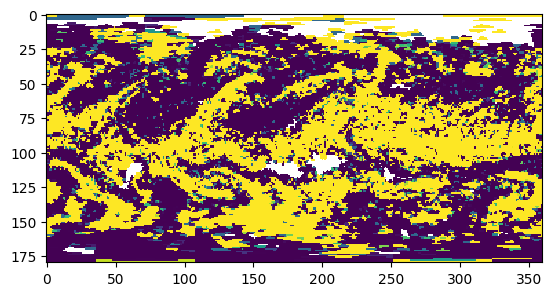

In [11]:
plt.imshow(model_data["ctp"].isel(time=0),interpolation="none")

In [33]:
new_data_list[0].time.dt.strftime("%Y-%m-%dT%H:%M:%S").item()

'2008-09-01T00:00:00'

In [26]:
out = CPH_output[1].assign_attrs({"name": "cph","long_name":"Cloud Phase","units":"unitless"}).rename("cph_filtered")

In [89]:
len(dataset_list)

96

In [ ]:

len(times)

96

In [20]:
def round_to_minute(dt: datetime) -> datetime:
    return (dt.replace(second=0, microsecond=0)
            + timedelta(minutes=1) if dt.second >= 30 else dt.replace(second=0, microsecond=0))

In [21]:
for i, cph_temp_range in enumerate(CPH_output):
    # group by time: one dataset per time step
    cph_temp_range = cph_temp_range.assign_attrs({"name": "cph","long_name":"Cloud Phase","units":"unitless"}).rename("cph_filtered")
    # convert times to datetimes
    # --- convert float time (YYYYMMDD + frac day) -> datetime64 ---
    t = cph_temp_range["time"].values.astype(float)
    ymd  = np.floor(t).astype(int)
    frac = t - ymd

    base = pd.to_datetime(ymd.astype(str), format="%Y%m%d")
    dt = ((base + pd.to_timedelta(frac, unit="D")).to_numpy(dtype="datetime64[ns]") + np.timedelta64(30, 's')).astype('datetime64[m]')
    
    cph_temp_range = cph_temp_range.assign_coords(time=("time", dt))
    times, dataset_list = zip(*cph_temp_range.to_dataset().groupby("time",squeeze=False))
    new_data_list = []
    for data,dt in zip(dataset_list,times):
        new_data_list.append(data.assign_coords(time=("time", [dt])))
        data = new_data_list[-1]
        data['time']= data['time'].assign_attrs({'standard_name': 'time',
                                                                    'axis': 'T'})
        data.time.encoding = {
            "units": "seconds since 2008-08-30 00:00:00",
            "calendar": "proleptic_gregorian",
        }
        data['lat']= data['lat'].assign_attrs({'_FillValue': np.nan ,
                                                                'standard_name': 'latitude',
                                                                'long_name': 'latitude',
                                                                'units': 'degrees_north',
                                                                'axis': 'Y'})
        data['lon']= data['lon'].assign_attrs({'_FillValue': np.nan ,
                                                                'standard_name': 'longitude',
                                                                'long_name': 'longitude',
                                                                'units': 'degrees_east',
                                                                'axis': 'X'})

/tmp/ipykernel_8324/1183950588.py:13: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  cph_temp_range = cph_temp_range.assign_coords(time=("time", dt))
/tmp/ipykernel_8324/1183950588.py:13: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting

## 3.1 File remap

In [41]:
# Cell 1: Imports
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.interpolate import griddata


In [42]:
# Cell 2: User settings
FILE = "/wolke_scratch/dnikolo/ICON_Data/Nudged_run_cph_09_02/test_input.nc"   # <- change this
VAR_NAME = "ctt"         # <- change this (e.g., cth, zct, etc.)
CLAT_NAME = "clat"
CLON_NAME = "clon"

TIME_INDEX = 0

# Target regular grid
LAT_MIN, LAT_MAX, DLAT = -90, 90, 0.25
LON_MIN, LON_MAX, DLON = -180, 180, 0.25

METHOD = "nearest"  # "nearest", "linear", or "cubic"


In [43]:
# Cell 3: Helper functions
def to_degrees_if_needed(arr):
    """Convert radians to degrees if values look like radians."""
    a = np.asarray(arr)
    finite = np.isfinite(a)
    if not np.any(finite):
        raise ValueError("Coordinate array has no finite values.")
    amin = np.nanmin(a[finite])
    amax = np.nanmax(a[finite])

    # Heuristic for radians
    if max(abs(amin), abs(amax)) <= 3.5:
        return np.degrees(a), True
    return a, False


def select_1d_field(da, time_index=0):
    """
    Reduce variable to 1D cell field:
    - select given time index if time dim exists
    - collapse remaining extra dims by taking first index
    """
    d = da

    # Handle time dimension (common names)
    time_dims = [dim for dim in d.dims if dim.lower() in ("time", "t")]
    if time_dims:
        tdim = time_dims[0]
        d = d.isel({tdim: time_index})

    # Reduce to 1D
    while d.ndim > 1:
        keep_dim = max(d.dims, key=lambda k: d.sizes[k])  # likely cell dim
        squeeze_dim = next(dim for dim in d.dims if dim != keep_dim)
        d = d.isel({squeeze_dim: 0})

    return d


In [44]:
# Cell 4: Open dataset and inspect
ds = xr.open_dataset(FILE)
print(ds)
print("\nVariables:", list(ds.variables))


<xarray.Dataset>
Dimensions:    (time: 96, ncells: 20480, vertices: 3)
Coordinates:
  * time       (time) float64 2.008e+07 2.008e+07 ... 2.008e+07 2.008e+07
    clon       (ncells) float32 ...
    clat       (ncells) float32 ...
Dimensions without coordinates: ncells, vertices
Data variables:
    clon_bnds  (ncells, vertices) float32 ...
    clat_bnds  (ncells, vertices) float32 ...
    ctp        (time, ncells) float64 ...
    ctt        (time, ncells) float64 ...
Attributes:
    CDI:                  Climate Data Interface version 2.3.0 (https://mpime...
    Conventions:          CF-1.6
    number_of_grid_used:  5
    grid_file_uri:        http://icon-downloads.mpimet.mpg.de/grids/public/ic...
    uuidOfHGrid:          6dffb27e-c162-11e6-bde4-f3bd241f4de0
    source:               git@git.iac.ethz.ch:hammoz/icon-hammoz.git@c6577d13...
    institution:          Max Planck Institute for Meteorology/Deutscher Wett...
    title:                ICON simulation
    history:              T

In [45]:
# Cell 5: Extract ICON data (unstructured) and coordinates
data = ds[VAR_NAME]
clat = ds[CLAT_NAME]
clon = ds[CLON_NAME]

data_1d = select_1d_field(data, time_index=TIME_INDEX).values
clat_1d = np.ravel(clat.values)
clon_1d = np.ravel(clon.values)

# Make lengths consistent
n = min(len(data_1d), len(clat_1d), len(clon_1d))
data_1d = np.ravel(data_1d)[:n]
clat_1d = clat_1d[:n]
clon_1d = clon_1d[:n]

# Convert rad -> deg if needed
clat_deg, lat_was_rad = to_degrees_if_needed(clat_1d)
clon_deg, lon_was_rad = to_degrees_if_needed(clon_1d)

# Normalize lon to [-180, 180]
clon_deg = ((clon_deg + 180) % 360) - 180

print(f"clat in radians converted: {lat_was_rad}")
print(f"clon in radians converted: {lon_was_rad}")
print(f"Valid points total: {np.isfinite(data_1d).sum()} / {len(data_1d)}")


clat in radians converted: True
clon in radians converted: True
Valid points total: 19615 / 20480


In [46]:
# Cell 6: Build target 2D regular grid
lats = np.arange(LAT_MIN, LAT_MAX + DLAT, DLAT)
lons = np.arange(LON_MIN, LON_MAX + DLON, DLON)
lon2d, lat2d = np.meshgrid(lons, lats)

print("Target grid shape:", lat2d.shape)


Target grid shape: (721, 1441)


In [47]:
# Cell 7: Interpolate/remap to regular grid
valid = np.isfinite(clat_deg) & np.isfinite(clon_deg) & np.isfinite(data_1d)

points = np.column_stack((clon_deg[valid], clat_deg[valid]))
values = data_1d[valid]

remapped = griddata(
    points=points,
    values=values,
    xi=(lon2d, lat2d),
    method=METHOD,
    fill_value=np.nan
)

remapped_da = xr.DataArray(
    remapped,
    dims=("lat", "lon"),
    coords={"lat": lats, "lon": lons},
    name=f"{VAR_NAME}_remapped"
)

remapped_da


<xarray.DataArray 'ctt_remapped' (lat: 721, lon: 1441)>
array([[243.41423617, 243.41423617, 243.41423617, ..., 248.22468174,
        248.22468174, 248.22468174],
       [243.41423617, 243.41423617, 243.41423617, ..., 248.22468174,
        248.22468174, 248.22468174],
       [243.41423617, 243.41423617, 243.41423617, ..., 248.22468174,
        248.22468174, 248.22468174],
       ...,
       [247.71926161, 247.71926161, 247.71926161, ..., 255.95349657,
        255.95349657, 255.95349657],
       [247.71926161, 247.71926161, 247.71926161, ..., 255.95349657,
        255.95349657, 255.95349657],
       [247.71926161, 247.71926161, 247.71926161, ..., 258.12512851,
        255.95349657, 255.95349657]])
Coordinates:
  * lat      (lat) float64 -90.0 -89.75 -89.5 -89.25 ... 89.25 89.5 89.75 90.0
  * lon      (lon) float64 -180.0 -179.8 -179.5 -179.2 ... 179.5 179.8 180.0

In [48]:
# Cell 9 (optional): Save remapped field to NetCDF
OUT_NC = f"{VAR_NAME}_remapped.nc"
remapped_da.to_dataset().to_netcdf(OUT_NC)
print("Saved:", OUT_NC)


Saved: ctt_remapped.nc


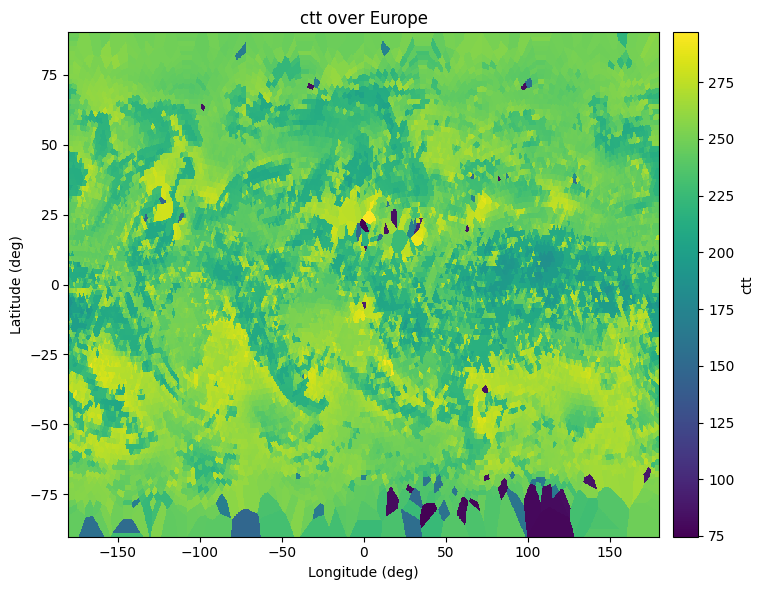

In [49]:
# Cell 10 (optional): Quick regional zoom example (Europe)
plt.figure(figsize=(8, 6))
mesh = plt.pcolormesh(lon2d, lat2d, remapped, shading="auto")
plt.colorbar(mesh, pad=0.02, label=VAR_NAME)
# plt.xlim(-15, 35)
# plt.ylim(30, 72)
plt.xlabel("Longitude (deg)")
plt.ylabel("Latitude (deg)")
plt.title(f"{VAR_NAME} over Europe")
plt.tight_layout()
plt.show()


## 3.2 Other

In [22]:
dt

numpy.datetime64('2008-09-01T23:45:00.000000000')

In [95]:
new_data_list[0].time.dt

In [46]:
CC_3d_mask_index = CC_3d_mask.argmax(dim='height')

In [47]:
#Remove values with no cloud 

CC_3d_check = ~CC_3d_mask.any(dim='height')
CC_3d_final = xr.where(CC_3d_check, -999, CC_3d_mask_index)

In [48]:
#---------------------------------------------------------------
#Temperature range loop
#---------------------------------------------------------------
T_ranges = [(i,i+6) for i in range(273-6, 273-38, -6)]


In [49]:
CPH = xr.where(CC_3d_mask,(CLDICE/CLDLIQ > 1)*1 +1,0)

In [50]:
CTT_results=[]
CPH_results=[]

In [51]:

# #---------------------------------------------------------------
# #setup arrays
# #---------------------------------------------------------------
# CRE_T_loop = []
# CC_T_loop = []

#---------------------------------------------------------------
#Cloud masking
#---------------------------------------------------------------
#Cloud cover masking



#TWC mask is 2d, it has either index of CT or -999 for no cloud



#---------------------------------------------------------------
#Temperature range loop
#---------------------------------------------------------------

for T_range in T_ranges:
    #Temperature bounds
    T_min, T_max = T_range
    #Mask cloudy gridboxes within T range
    CTT_mask = (TWC > TWC_threshold) & (T >= T_min) & (T < T_max)
    #Find lowest level where condition is met (highest since reversed)
    CTT_index = CTT_mask.argmax(dim='height')

    #If gridbox has a cloud + highest cloudy point is within temperature range -> cloud has right CTT
    CTT_filter = (CTT_index == CC_3d_final)

    #Apply mask
    CPH_results.append(CPH.where(CTT_filter).max(dim='height'))
    CTT_results.append(T.where(CTT_filter).max(dim='height'))
    
    # #Compute averages
    # CRE_mean = CRE_CTT.mean(dim=('time', 'lat', 'lon'), skipna=True)
    # CRE_T_loop.append(CRE_mean)

    #Compute cloud cover lazily
    # cloudy_gp = CRE_CTT.notnull().sum(dim=('time', 'lat', 'lon'))
    # total_gp = CRE.notnull().sum(dim=('time', 'lat', 'lon'))
    # cloud_fraction = cloudy_gp / total_gp

    # CC_T_loop.append(cloud_fraction)







In [52]:
#---------------------------------------------------------------
#Dask lazy computation
#---------------------------------------------------------------
# Compute all cloud cover values in parallel
with ProgressBar(dt=15.0):
    (
        CTT_output,
        CPH_output

    ) = dask.compute(
        CPH_results,
        CTT_results
    )

[########################################] | 100% Completed | 15.02 s


In [57]:
CPH_results

[<xarray.DataArray (time: 96, lat: 67, lon: 240)>
 dask.array<_nanmax_skip-aggregate, shape=(96, 67, 240), dtype=float64, chunksize=(1, 67, 240), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float64 2.008e+07 2.008e+07 ... 2.008e+07 2.008e+07
   * lon      (lon) float64 -179.5 -178.0 -176.5 -175.0 ... 176.0 177.5 179.0
   * lat      (lat) float64 -79.0 -77.5 -76.0 -74.5 -73.0 ... 75.5 77.0 78.5 80.0,
 <xarray.DataArray (time: 96, lat: 67, lon: 240)>
 dask.array<_nanmax_skip-aggregate, shape=(96, 67, 240), dtype=float64, chunksize=(1, 67, 240), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float64 2.008e+07 2.008e+07 ... 2.008e+07 2.008e+07
   * lon      (lon) float64 -179.5 -178.0 -176.5 -175.0 ... 176.0 177.5 179.0
   * lat      (lat) float64 -79.0 -77.5 -76.0 -74.5 -73.0 ... 75.5 77.0 78.5 80.0,
 <xarray.DataArray (time: 96, lat: 67, lon: 240)>
 dask.array<_nanmax_skip-aggregate, shape=(96, 67, 240), dtype=float64, chunksize=(1, 67, 240), chunktype=numpy.

In [61]:
dataset_list

(<xarray.DataArray 'ta' (lat: 67, lon: 240)>
 array([[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]])
 Coordinates:
     time     float64 2.008e+07
   * lon      (lon) float64 -179.5 -178.0 -176.5 -175.0 ... 176.0 177.5 179.0
   * lat      (lat) float64 -79.0 -77.5 -76.0 -74.5 -73.0 ... 75.5 77.0 78.5 80.0,
 <xarray.DataArray 'ta' (lat: 67, lon: 240)>
 array([[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]])
 Coordinates:
     time     float64 2.008e+07
   * lon      (lon) float64 -179.5 -178.0 -176.5 -175.0 ... 176.0 177.5 179.0
   * lat   

In [ ]:
base_dir = "/wolke_scratch/dnikolo/ICON_Data/Cloud_top_data_sample/Filtered_Data"
for i, cph_temp_range in enumerate(CPH_output):
    # group by time: one dataset per time step
    times, dataset_list = zip(*cph_temp_range.to_dataset().groupby("time"))

    # convert times to datetimes
    dts = [float_time_to_datetime(t) for t in times]

    # build one path per dataset in the desired format:
    # 2008/02/01/R_Agg_20_T_06_00_20080201000000.nc
    paths = []
    for dt in dts:
        subdir = dt.strftime("%Y/%m/%d")
        filename = f"R_Agg_30_T_{(273-T_ranges[i][0]):02}_{(273-T_ranges[i][1]):02}_{dt.strftime('%Y%m%d%H%M%S')}.nc"
        full_path = os.path.join(base_dir, subdir, filename)

        # make sure directory exists
        os.makedirs(os.path.dirname(full_path), exist_ok=True)
        paths.append(full_path)
    xr.save_mfdataset(dataset_list, paths)
    

In [84]:
cph_temp_range.to_dataset()

<xarray.Dataset>
Dimensions:  (time: 96, lon: 240, lat: 67)
Coordinates:
  * time     (time) float64 2.008e+07 2.008e+07 ... 2.008e+07 2.008e+07
  * lon      (lon) float64 -179.5 -178.0 -176.5 -175.0 ... 176.0 177.5 179.0
  * lat      (lat) float64 -79.0 -77.5 -76.0 -74.5 -73.0 ... 75.5 77.0 78.5 80.0
Data variables:
    ta       (time, lat, lon) float64 nan nan nan nan nan ... nan nan nan nan

In [ ]:
for i,cph_temp_range in enumerate(CPH_output):
     _, dataset_list = zip(*(CPH_output[0].groupby("time")))
    xr.save_mfdataset(dataset_list, os.path.join(f"CPH_T_{273-T_ranges[i][0]}_{273-T_ranges[i][1]}.nc"))
#     cph_temp_range.to_netcdf(os.path.join(array_path,f"CPH_T_{273-T_ranges[i][0]}_{273-T_ranges[i][1]}.nc"))

In [55]:
#---------------------------------------------------------------
#Save arrays
#---------------------------------------------------------------
name = '_' + file.split('.')[0]

np.save(array_path + 'CRE' + name, CRE_mean_output)
np.save(array_path + 'CC' + name, CC_output)

NameError: name 'CRE_mean_output' is not defined

## 4 Other

In [13]:
atm_data_3d["height"]

<xarray.DataArray 'height' (height: 47)>
array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14.,
       15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25., 26., 27., 28.,
       29., 30., 31., 32., 33., 34., 35., 36., 37., 38., 39., 40., 41., 42.,
       43., 44., 45., 46., 47.])
Coordinates:
  * height   (height) float64 1.0 2.0 3.0 4.0 5.0 ... 43.0 44.0 45.0 46.0 47.0
Attributes:
    standard_name:  height
    long_name:      generalized_height
    axis:           Z
    bounds:         height_bnds

In [40]:
atm_data_3d

<xarray.Dataset>
Dimensions:      (time: 96, lon: 240, lat: 120, height: 47, bnds: 2)
Coordinates:
  * time         (time) float64 2.008e+07 2.008e+07 ... 2.008e+07 2.008e+07
  * lon          (lon) float64 -179.5 -178.0 -176.5 -175.0 ... 176.0 177.5 179.0
  * lat          (lat) float64 -89.5 -88.0 -86.5 -85.0 ... 84.5 86.0 87.5 89.0
  * height       (height) float64 1.0 2.0 3.0 4.0 5.0 ... 44.0 45.0 46.0 47.0
Dimensions without coordinates: bnds
Data variables: (12/14)
    height_bnds  (height, bnds) float64 ...
    ps           (time, lat, lon) float64 ...
    pfull        (time, height, lat, lon) float64 ...
    zg           (height, lat, lon) float64 ...
    rho          (time, height, lat, lon) float64 ...
    ta           (time, height, lat, lon) float64 ...
    ...           ...
    wap          (time, height, lat, lon) float64 ...
    hus          (time, height, lat, lon) float64 ...
    clw          (time, height, lat, lon) float64 ...
    cli          (time, height, lat, lon) float64 ...
    hur          (time, height, lat, lon) float64 ...
    cl           (time, height, lat, lon) float64 ...
Attributes:
    CDI:          Climate Data Interface version 2.3.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    uuidOfVGrid:  491bfcac-b1d1-bcaf-6c12-f110853a2d00
    source:       Unknown@Unknown
    institution:  Max Planck Institute for Meteorology/Deutscher Wetterdienst
    title:        ICON simulation
    history:      Wed Nov 19 15:36:13 2025: cdo -remap,grid_1x1.txt,weights_3...
    references:   see MPIM/DWD publications
    comment:      Ryan Vella, ETHZ (rvella) on nid005237 (Linux 5.14.21-15050...
    CDO:          Climate Data Operators version 2.3.0 (https://mpimet.mpg.de...

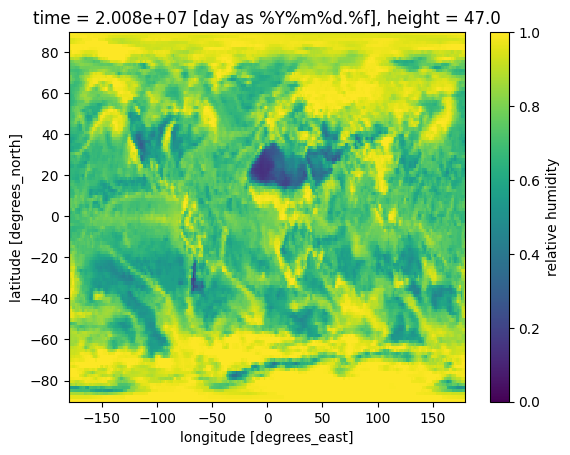

In [69]:
atm_data_3d_1_timesep = atm_data_3d.isel(time=0,height=46)
(atm_data_3d_1_timesep["hur"]).plot(vmin=0)

In [18]:
import metpy.calc as mpcalc

In [ ]:
atm_data_3d["height_bnds"].isel(bnds=1).values

array([ 2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14.,
       15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25., 26., 27.,
       28., 29., 30., 31., 32., 33., 34., 35., 36., 37., 38., 39., 40.,
       41., 42., 43., 44., 45., 46., 47., 48.])

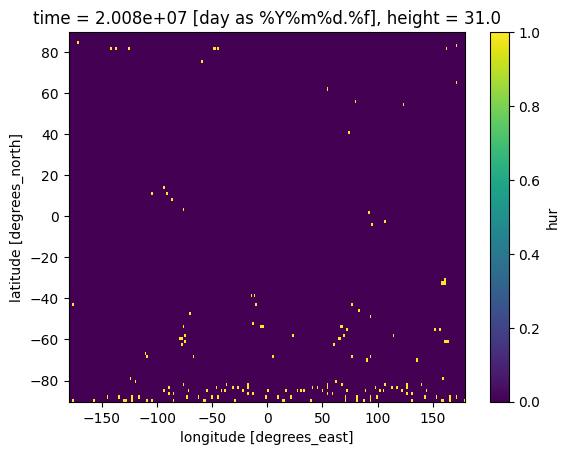

In [35]:
(atm_data_3d_1_timesep["hur"]>1).plot()


In [41]:
mpcalc.relative_humidity_from_specific_humidity(atm_data_3d_1_timesep["pfull"],atm_data_3d_1_timesep["ta"],atm_data_3d_1_timesep["hus"])

Magnitude,[[0.7826976271747622 0.7825005401768664 0.7823035394692546 ... 0.7832850600224457 0.7830903468826034 0.7828943784718867] [0.6577356850384535 0.6577715542908444 0.6577622188210968 ... 0.6982255153889496 0.6964073773147219 0.65943680788441] [0.4453245051658273 0.4403466364121338 0.43576977682339696 ... 0.5692167637004764 0.5680072775093078 0.5671359317007485] ... [0.5901546943289605 0.5930611638726162 0.5965278747258378 ... 0.5951284987301487 0.5930598604102082 0.5904823505744659] [0.4999794591417701 0.5020670163432982 0.5041397545677317 ... 0.49019404673403594 0.4919162212642519 0.4935558401916976] [0.47034694417754697 0.4705073291140631 0.4707685332067541 ... 0.470541656853908 0.4704111250365389 0.47032407662928355]]
Units,dimensionless


In [4]:
atm_data_2d = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/atm_2d_remap_test.nc")

In [ ]:
atm_data_2d

<xarray.Dataset>
Dimensions:   (time: 96, lon: 240, lat: 120, height: 1, height_2: 1, lev: 1)
Coordinates:
  * time      (time) float64 2.008e+07 2.008e+07 ... 2.008e+07 2.008e+07
  * lon       (lon) float64 -179.5 -178.0 -176.5 -175.0 ... 176.0 177.5 179.0
  * lat       (lat) float64 -89.5 -88.0 -86.5 -85.0 ... 84.5 86.0 87.5 89.0
  * height    (height) float64 10.0
  * height_2  (height_2) float64 2.0
  * lev       (lev) float64 0.0
Data variables: (12/41)
    ps        (time, lat, lon) float64 ...
    psl       (time, lat, lon) float64 ...
    cosmu0    (time, lat, lon) float64 ...
    rsdt      (time, lat, lon) float64 ...
    rsut      (time, lat, lon) float64 ...
    rsutcs    (time, lat, lon) float64 ...
    ...        ...
    uas       (time, height, lat, lon) float64 ...
    vas       (time, height, lat, lon) float64 ...
    tas       (time, height_2, lat, lon) float64 ...
    dew2      (time, height_2, lat, lon) float64 ...
    ptp       (time, lev, lat, lon) float64 ...
    hdtcbl    (time, lat, lon) float64 ...
Attributes:
    CDI:          Climate Data Interface version 2.3.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       Unknown@Unknown
    institution:  Max Planck Institute for Meteorology/Deutscher Wetterdienst
    title:        ICON simulation
    history:      Tue Nov 18 16:20:21 2025: cdo -remap,grid_1x1.txt,weights.n...
    references:   see MPIM/DWD publications
    comment:      Ryan Vella, ETHZ (rvella) on nid005237 (Linux 5.14.21-15050...
    CDO:          Climate Data Operators version 2.3.0 (https://mpimet.mpg.de...

In [5]:
import matplotlib.pyplot as plt

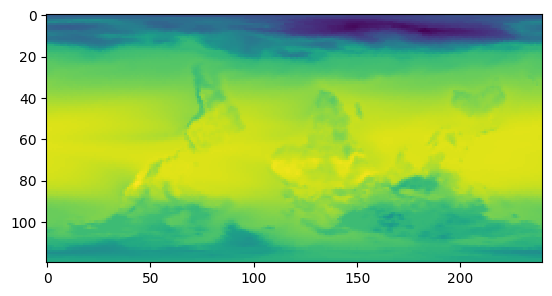

In [6]:
plt.imshow(atm_data_2d['ts'].isel(time=0),interpolation='none')

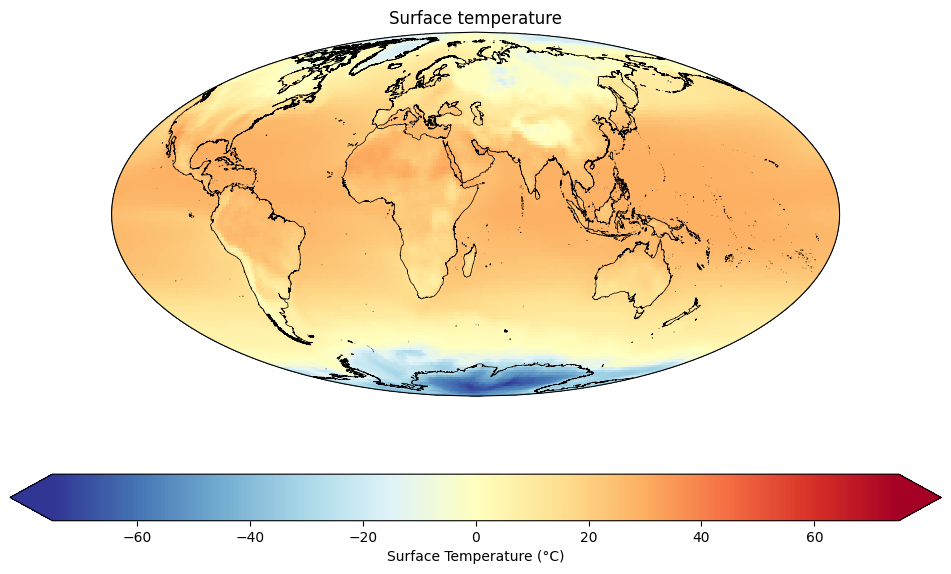

In [7]:
proj = ccrs.Mollweide(50.) # Create Mollweide projections
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection=proj)
plot = (atm_data_2d['ts'].isel(time=2)-273).plot(
                      ax=ax,
                      transform=ccrs.PlateCarree(),
                      cmap='RdYlBu_r',
                    #   vmin=-120,
                    #   vmax=120,
                      cbar_kwargs={'label': 'Surface Temperature (°C)',
                                   'extend': 'both',
                                   'shrink': .8,
                                   'orientation': 'horizontal'},
 
                     )
ax.coastlines(resolution='10m', lw=0.51)
ax.set_title(f'Surface temperature')
_ = fig.subplots_adjust(left=0.01, right=0.98, hspace=0, wspace=0, top=0.9, bottom=0.25)

In [8]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.animation import FuncAnimation

# Take data in °C and precompute vmin/vmax so colors stay consistent across frames
data = atm_data_2d['ts'] - 273  # (time, lat, lon)
vmin = float(data.min())
vmax = float(data.max())

proj = ccrs.Mollweide(50.)  # Create Mollweide projection
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection=proj)

# First frame (time=0); create the plot and colorbar only once
plot = data.isel(time=0).plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap='RdYlBu_r',
    vmin=vmin,
    vmax=vmax,
    add_colorbar=True,
    cbar_kwargs={
        'label': 'Surface Temperature (°C)',
        'extend': 'both',
        'shrink': .8,
        'orientation': 'horizontal'
    },
)

ax.coastlines(resolution='10m', lw=0.51)
time0 = data.time.isel(time=0).values
ax.set_title(f'Surface temperature, time={str(time0)}')
fig.subplots_adjust(left=0.01, right=0.98, hspace=0, wspace=0, top=0.9, bottom=0.25)

# Update function for each frame
def update(frame):
    da = data.isel(time=frame)
    # xarray's pcolormesh-based plot stores data in plot QuadMesh
    # We update its array in-place:
    plot.set_array(da.values.ravel())

    t = da.time.values
    ax.set_title(f'Surface temperature, time={str(t)}')

    return [plot]

# Build animation over all timesteps
anim = FuncAnimation(
    fig,
    update,
    frames=data.sizes['time'],
    interval=200,  # milliseconds between frames
    blit=False     # blit can cause issues with cartopy; safer off
)

# Save as MP4 (requires ffmpeg installed)
anim.save('surface_temperature.mp4', writer='ffmpeg', dpi=150)
plt.close(fig)

/wolke_scratch/dnikolo/flex_trkr_env/lib/python3.11/site-packages/matplotlib/colors.py:1370: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin
/wolke_scratch/dnikolo/flex_trkr_env/lib/python3.11/site-packages/matplotlib/colors.py:732: RuntimeWarning: overflow encountered in multiply
  xa *= self.N
/wolke_scratch/dnikolo/flex_trkr_env/lib/python3.11/site-packages/matplotlib/colors.py:1370: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin
/wolke_scratch/dnikolo/flex_trkr_env/lib/python3.11/site-packages/matplotlib/colors.py:732: RuntimeWarning: overflow encountered in multiply
  xa *= self.N
/wolke_scratch/dnikolo/flex_trkr_env/lib/python3.11/site-packages/matplotlib/colors.py:1370: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin
/wolke_scratch/dnikolo/flex_trkr_env/lib/python3.11/site-packages/matplotlib/colors.py:732: RuntimeWarning: overflow encountered in multiply
  xa *= self.N
/wolke_scratch/dnikolo/flex_trkr_env/lib

In [9]:
from IPython.display import HTML
HTML(anim.to_html5_video())


AttributeError: QuadMesh.set() got an unexpected keyword argument 'intrpolation'

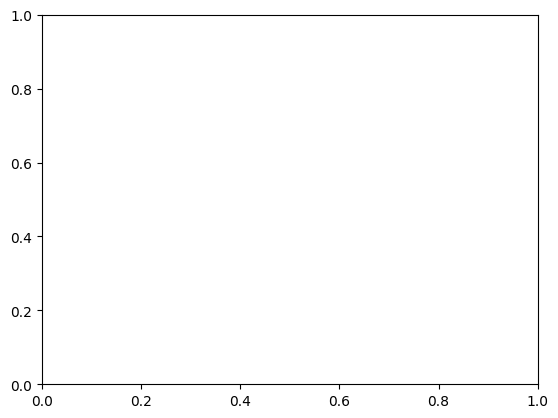

In [ ]:
(atm_data_2d['ts'].isel(time=0)-273.15).plot(intrpolation='none')

In [9]:
import matplotlib.pyplot as plt

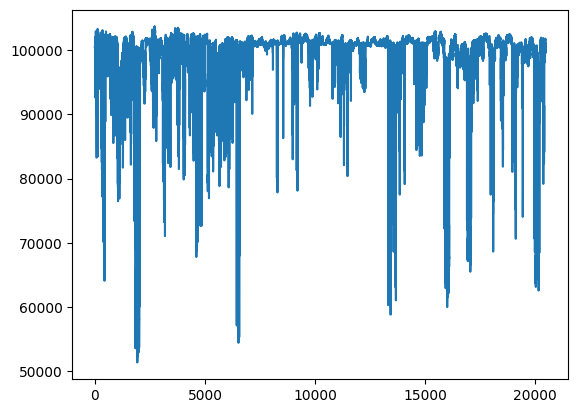

In [ ]:
plt.plot(atm_data_2d["ps"].isel(time=1))

In [16]:
atm_3d_data = xr.open_dataset("/wolke_scratch/rvella/shared/dragomir/test01/test01_atm_3d_ml_20080830T000000Z.nc",group="time_mean")

OSError: [Errno group not found: time_mean] 'time_mean'

In [ ]:
atm_data_2d['']

<xarray.Dataset>
Dimensions:    (ncells: 20480, vertices: 3, height: 1, height_2: 1, lev: 1,
                time: 96)
Coordinates:
    clon       (ncells) float32 ...
    clat       (ncells) float32 ...
  * height     (height) float64 10.0
  * height_2   (height_2) float64 2.0
  * lev        (lev) float64 0.0
  * time       (time) float64 2.008e+07 2.008e+07 ... 2.008e+07 2.008e+07
Dimensions without coordinates: ncells, vertices
Data variables: (12/43)
    clon_bnds  (ncells, vertices) float32 ...
    clat_bnds  (ncells, vertices) float32 ...
    ps         (time, ncells) float64 ...
    psl        (time, ncells) float64 ...
    cosmu0     (time, ncells) float64 ...
    rsdt       (time, ncells) float64 ...
    ...         ...
    uas        (time, height, ncells) float64 ...
    vas        (time, height, ncells) float64 ...
    tas        (time, height_2, ncells) float64 ...
    dew2       (time, height_2, ncells) float64 ...
    ptp        (time, lev, ncells) float64 ...
    hdtcbl     (time, ncells) float64 ...
Attributes:
    CDI:                  Climate Data Interface version 1.8.3rc (http://mpim...
    Conventions:          CF-1.6
    number_of_grid_used:  5
    grid_file_uri:        http://icon-downloads.mpimet.mpg.de/grids/public/ic...
    uuidOfHGrid:          6dffb27e-c162-11e6-bde4-f3bd241f4de0
    institution:          Max Planck Institute for Meteorology/Deutscher Wett...
    title:                ICON simulation
    source:               Unknown@Unknown
    history:              /users/rvella/git/icon-hammoz-psrad-nudging/bin/ico...
    references:           see MPIM/DWD publications
    comment:              Ryan Vella, ETHZ (rvella) on nid005237 (Linux 5.14....

In [12]:
atm_3d_data

<xarray.Dataset>
Dimensions:      (ncells: 20480, vertices: 3, height: 47, bnds: 2, time: 96)
Coordinates:
    clon         (ncells) float32 ...
    clat         (ncells) float32 ...
  * height       (height) float64 1.0 2.0 3.0 4.0 5.0 ... 44.0 45.0 46.0 47.0
  * time         (time) float64 2.008e+07 2.008e+07 ... 2.008e+07 2.008e+07
Dimensions without coordinates: ncells, vertices, bnds
Data variables: (12/16)
    clon_bnds    (ncells, vertices) float32 ...
    clat_bnds    (ncells, vertices) float32 ...
    height_bnds  (height, bnds) float64 ...
    ps           (time, ncells) float64 ...
    pfull        (time, height, ncells) float64 ...
    zg           (height, ncells) float64 ...
    ...           ...
    wap          (time, height, ncells) float64 ...
    hus          (time, height, ncells) float64 ...
    clw          (time, height, ncells) float64 ...
    cli          (time, height, ncells) float64 ...
    hur          (time, height, ncells) float64 ...
    cl           (time, height, ncells) float64 ...
Attributes:
    CDI:                  Climate Data Interface version 1.8.3rc (http://mpim...
    Conventions:          CF-1.6
    number_of_grid_used:  5
    grid_file_uri:        http://icon-downloads.mpimet.mpg.de/grids/public/ic...
    uuidOfHGrid:          6dffb27e-c162-11e6-bde4-f3bd241f4de0
    uuidOfVGrid:          491bfcac-b1d1-bcaf-6c12-f110853a2d00
    institution:          Max Planck Institute for Meteorology/Deutscher Wett...
    title:                ICON simulation
    source:               Unknown@Unknown
    history:              /users/rvella/git/icon-hammoz-psrad-nudging/bin/ico...
    references:           see MPIM/DWD publications
    comment:              Ryan Vella, ETHZ (rvella) on nid005237 (Linux 5.14....